# Application d'un VAE avec PyTorch
### Exemple au travers du jeu de donnée MNIST (mais faisable en 1D, 2D ou 3D)

## 1. Import des bibliothèques python

In [97]:
%load_ext autoreload
import os
import numpy as np
import pandas as pd
import scipy.stats
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as Funct

# personnal
import libraries
import libraries.data_loader as dl
from libraries.gen_masks import get_masks

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 2. Load MNIST

In [98]:
path = r"datas/mnist.npz"
(X_train, Y_train), (X_val, Y_val) = dl.load_datas(path)
X_train = X_train.reshape((60000, 1, 28, 28))
X_val = X_val[:].reshape((10000, 1, 28, 28))



X_train.shape, X_val.shape

((60000, 1, 28, 28), (10000, 1, 28, 28))

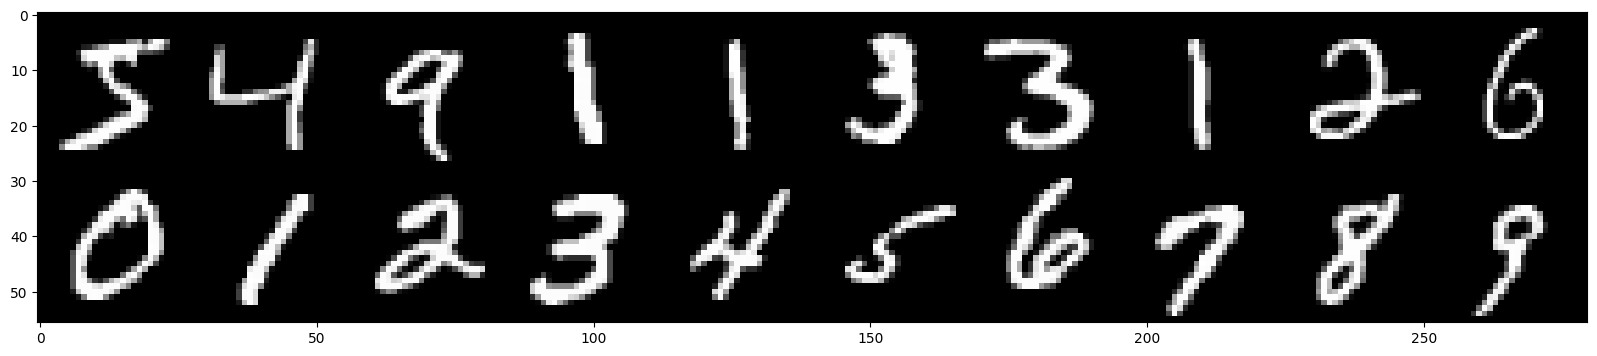

In [99]:
index = 20
images = np.array(X_train[:index].mean(axis = 1), dtype = np.float32) /256
# images = exp_softmax(images)

cols = 10
new_images = images.reshape((cols, index//cols,) + X_train.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images, cmap = 'gray')

# Get MUS and STDS 

In [110]:
%autoreload 2

batchsize = 1000
batch_range_train = range(0, X_train.shape[0] +1, batchsize) # X_train.shape[0] +1

MASKS, MUS, STDS = [], [], []
for i, batch in enumerate(batch_range_train[:-1]) :
    
    X = np.array(X_train[batch:batch_range_train[i +1]], dtype = np.float32)/255.
    masks, mus, stds = get_masks(X, 3, seed = i)
    MASKS.append(np.array(masks))
    MUS.append(np.array(mus))
    STDS.append(np.array(stds))

MASKS = np.concatenate(MASKS)
MUS = np.concatenate(MUS)
STDS = np.concatenate(STDS)

MASKS = (MASKS*255).astype(np.uint8)
MASKS.shape, MUS.shape, STDS.shape

((60000, 28, 28), (60000, 2), (60000, 2))

In [131]:
filepath = r"datas/rt-mnist.npz"
if not os.path.isfile(filepath) :
    np.savez(filepath, masks = MASKS, mus = MUS, stds = STDS, allow_pickle=False)

In [128]:
X_STRUCT = X_train[:50].astype(np.float32)
X_STRUCT[np.where(X_STRUCT > 0)] = 1.

DOSE = MASKS[:50].astype(np.float32) /255
X_DOSE = X_STRUCT*DOSE.reshape(X_STRUCT.shape)
X_DOSE.shape

(50, 1, 28, 28)

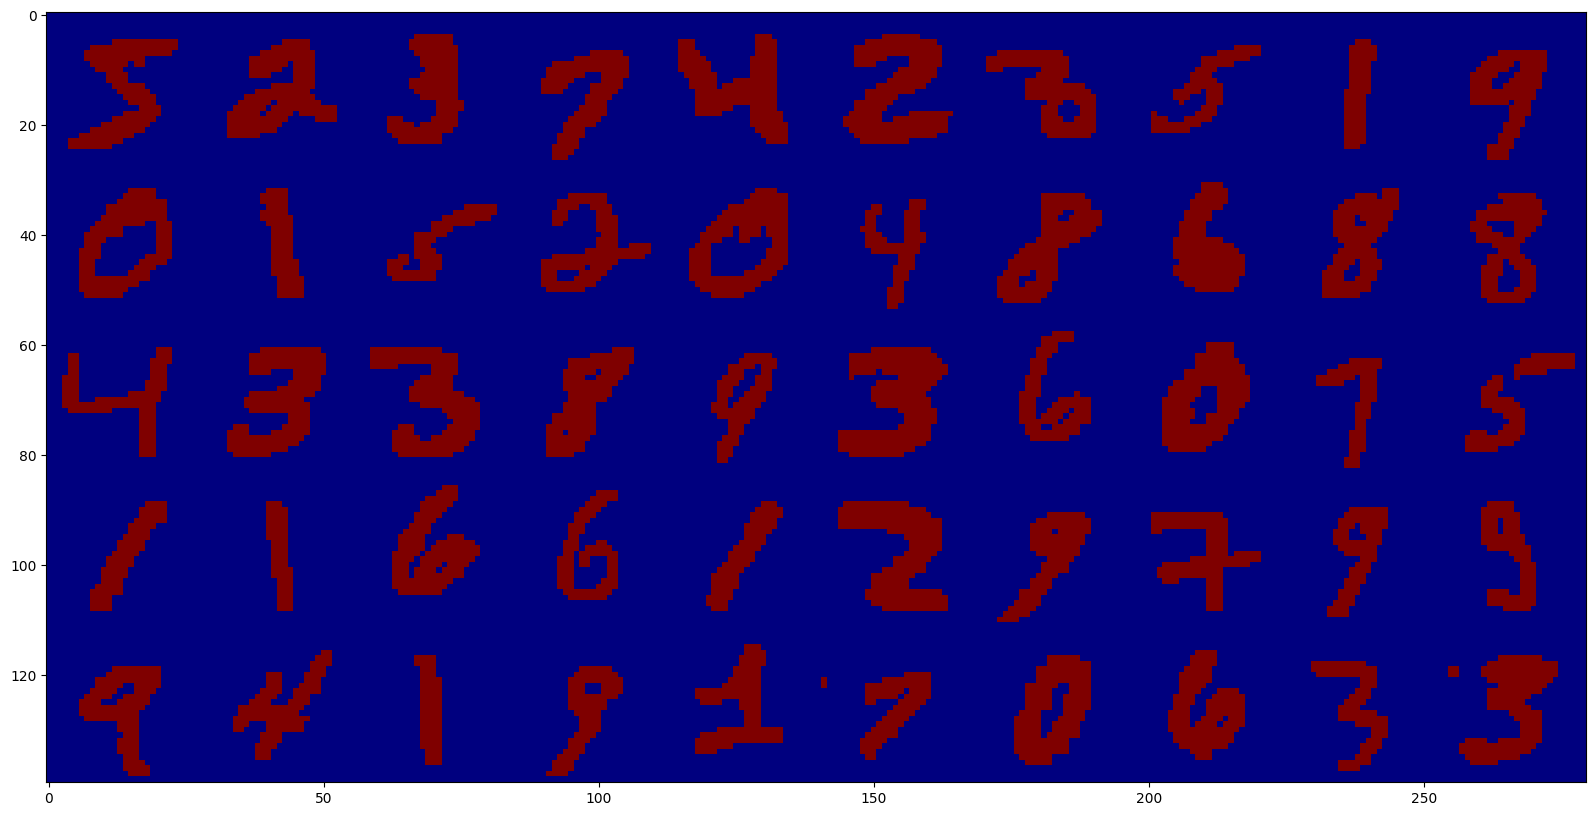

In [129]:
index = 50
images = np.array(X_STRUCT[:index], dtype = np.float32) /256
# images = exp_softmax(images)


new_images = images.reshape((10, 5,) + X_test.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images, cmap = 'jet')

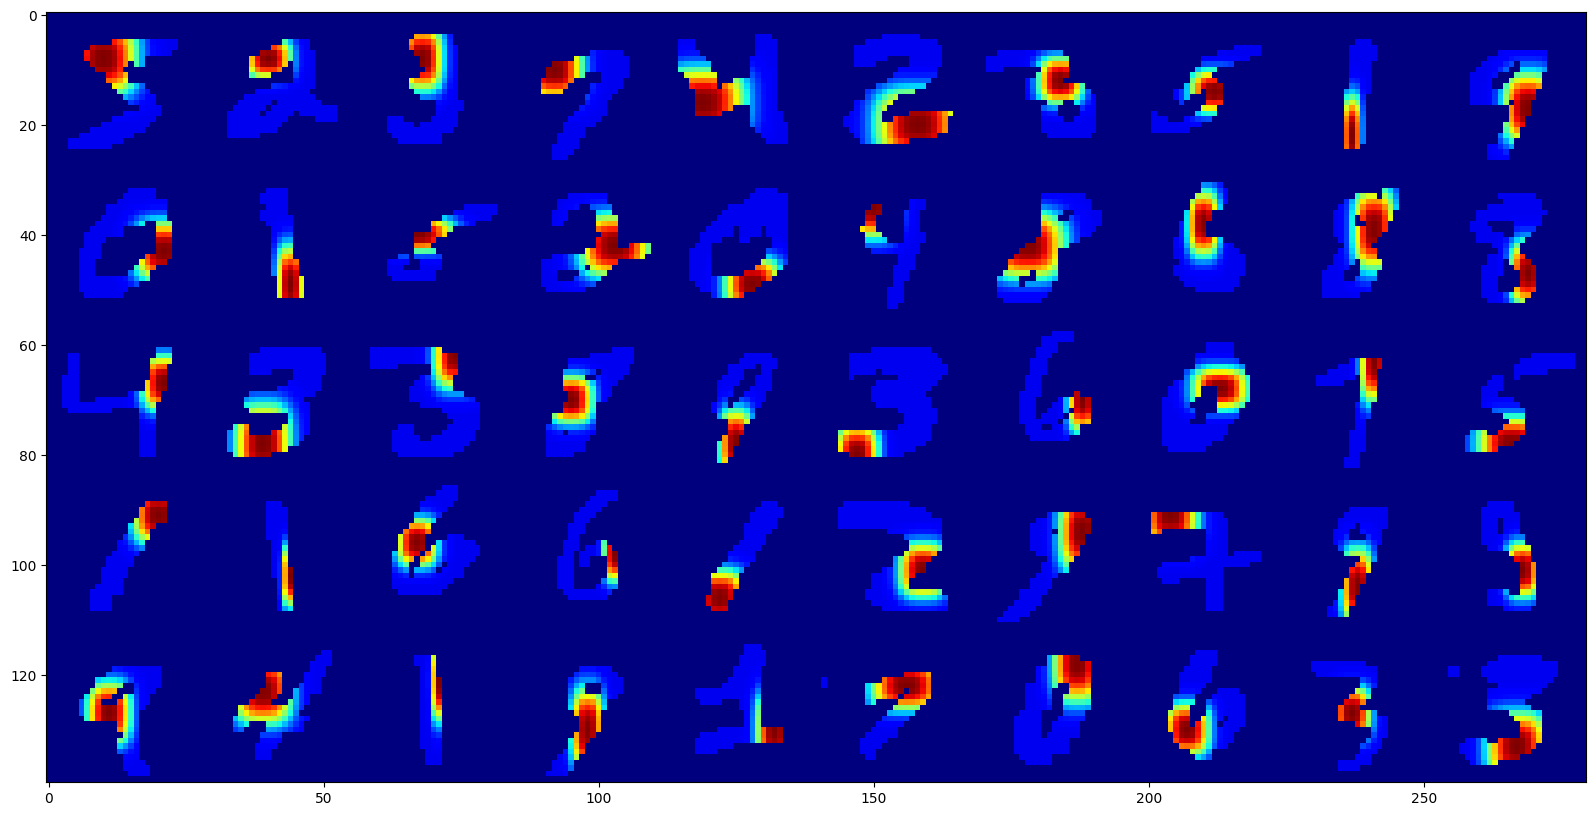

In [130]:
index = 50
images = np.array(X_DOSE[:index], dtype = np.float32) /256
# images = exp_softmax(images)


new_images = images.reshape((10, 5,) + RT_X_test.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images, cmap = 'jet')

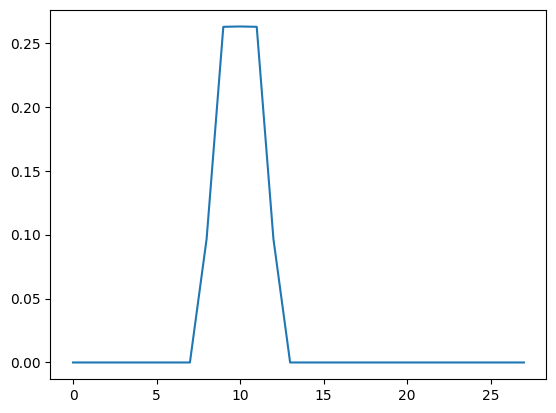

In [61]:
x = np.arange(28)
y = scipy.stats.gennorm.pdf(x, 10, 10, 2)
plt.plot(x, y)

## 3. Get mask for TOX

In [3]:
(X_train, All_Y_train), (All_X_val, All_Y_val) = ld.load_data('../../../DATAS/mnist.npz') # Thèses\Benchmark\CVAE 2D
X_train = X_train.reshape((60000, 28, 28))
All_X_val = All_X_val[:].reshape((10000, 28, 28))

In [4]:
(new_X_train, All_Y_train), (new_X_val, All_Y_val) = ld.load_data('../../../DATAS/mnist_modified.npz') # Thèses\Benchmark\CVAE 2D
new_X_train = new_X_train.reshape((60000, 28, 28))
new_X_val = new_X_val[:].reshape((10000, 28, 28))

In [10]:
(new_X_train, All_Y_train), (new_X_val, All_Y_val) = ld.load_data('../../../DATAS/mnist_masked.npz') # Thèses\Benchmark\CVAE 2D
new_X_train = new_X_train.reshape((60000, 28, 28))
new_X_val = new_X_val[:].reshape((10000, 28, 28))

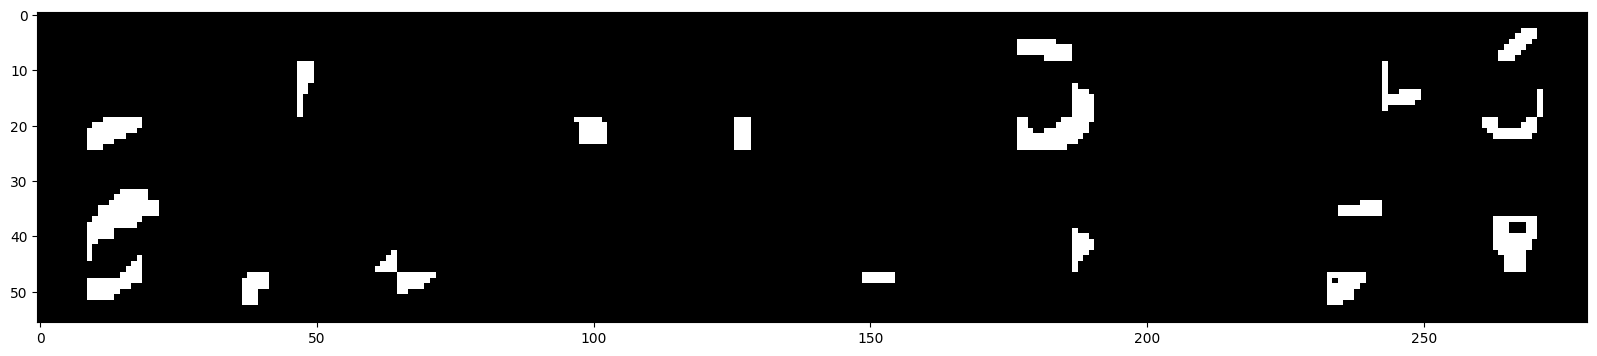

In [14]:
index = 20
images = np.array(new_X_train[:index], dtype = np.float32) /256
# images = exp_softmax(images)


new_images = images.reshape((10, index//10,) + new_X_train.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images, cmap = "gray")

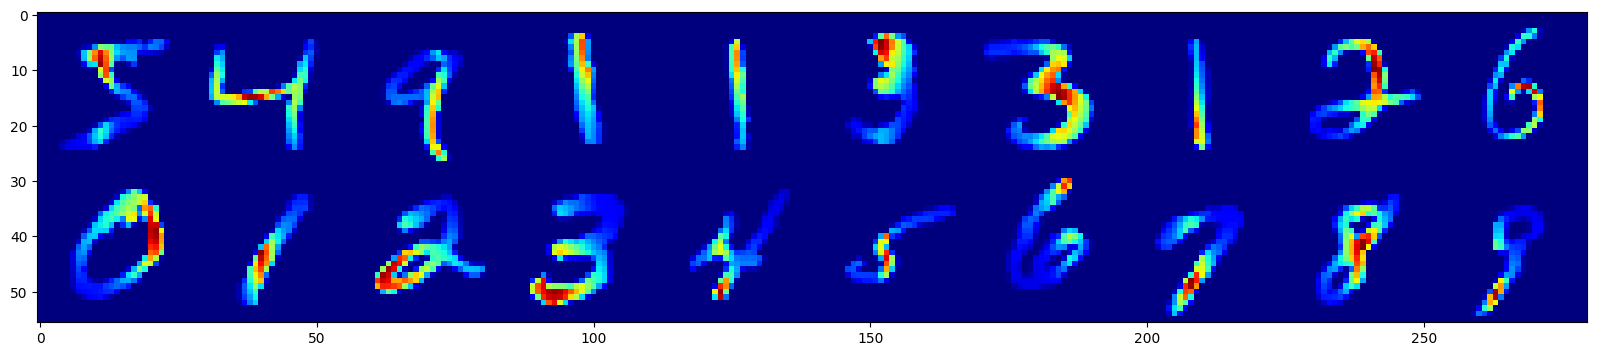

In [9]:
index = 20
images = np.array(new_X_train[:index], dtype = np.float32)
# images = exp_softmax(images)


new_images = images.reshape((10, index//10,) + new_X_train.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images, cmap = 'jet')

In [88]:
elem.shape

(60000, 9)

In [102]:
curr_X = new_X_val.copy()

problem = np.array([[False for i in range(9)]]*curr_X.shape[0]).reshape((curr_X.shape[0], 3, 3))
indic = np.array([[-1 for i in range(9)]]*curr_X.shape[0]).reshape((curr_X.shape[0], 3, 3))

rang = [0, 9, 19, 28]
for i in range(len(rang) -1) :
    for j in range(len(rang) -1) :
        elem = curr_X[:, rang[i]:rang[i +1], rang[j]:rang[j +1]]
        indic[:, i, j] = np.sqrt((np.max(elem, axis = (1, 2)) -np.min(elem, axis = (1, 2)))*np.mean(elem, axis = (1, 2)))

for i, cur_indic in enumerate(indic) :
    problem[i, :] = (cur_indic > cur_indic.max()/3) & (cur_indic < 2 *cur_indic.max()/3)

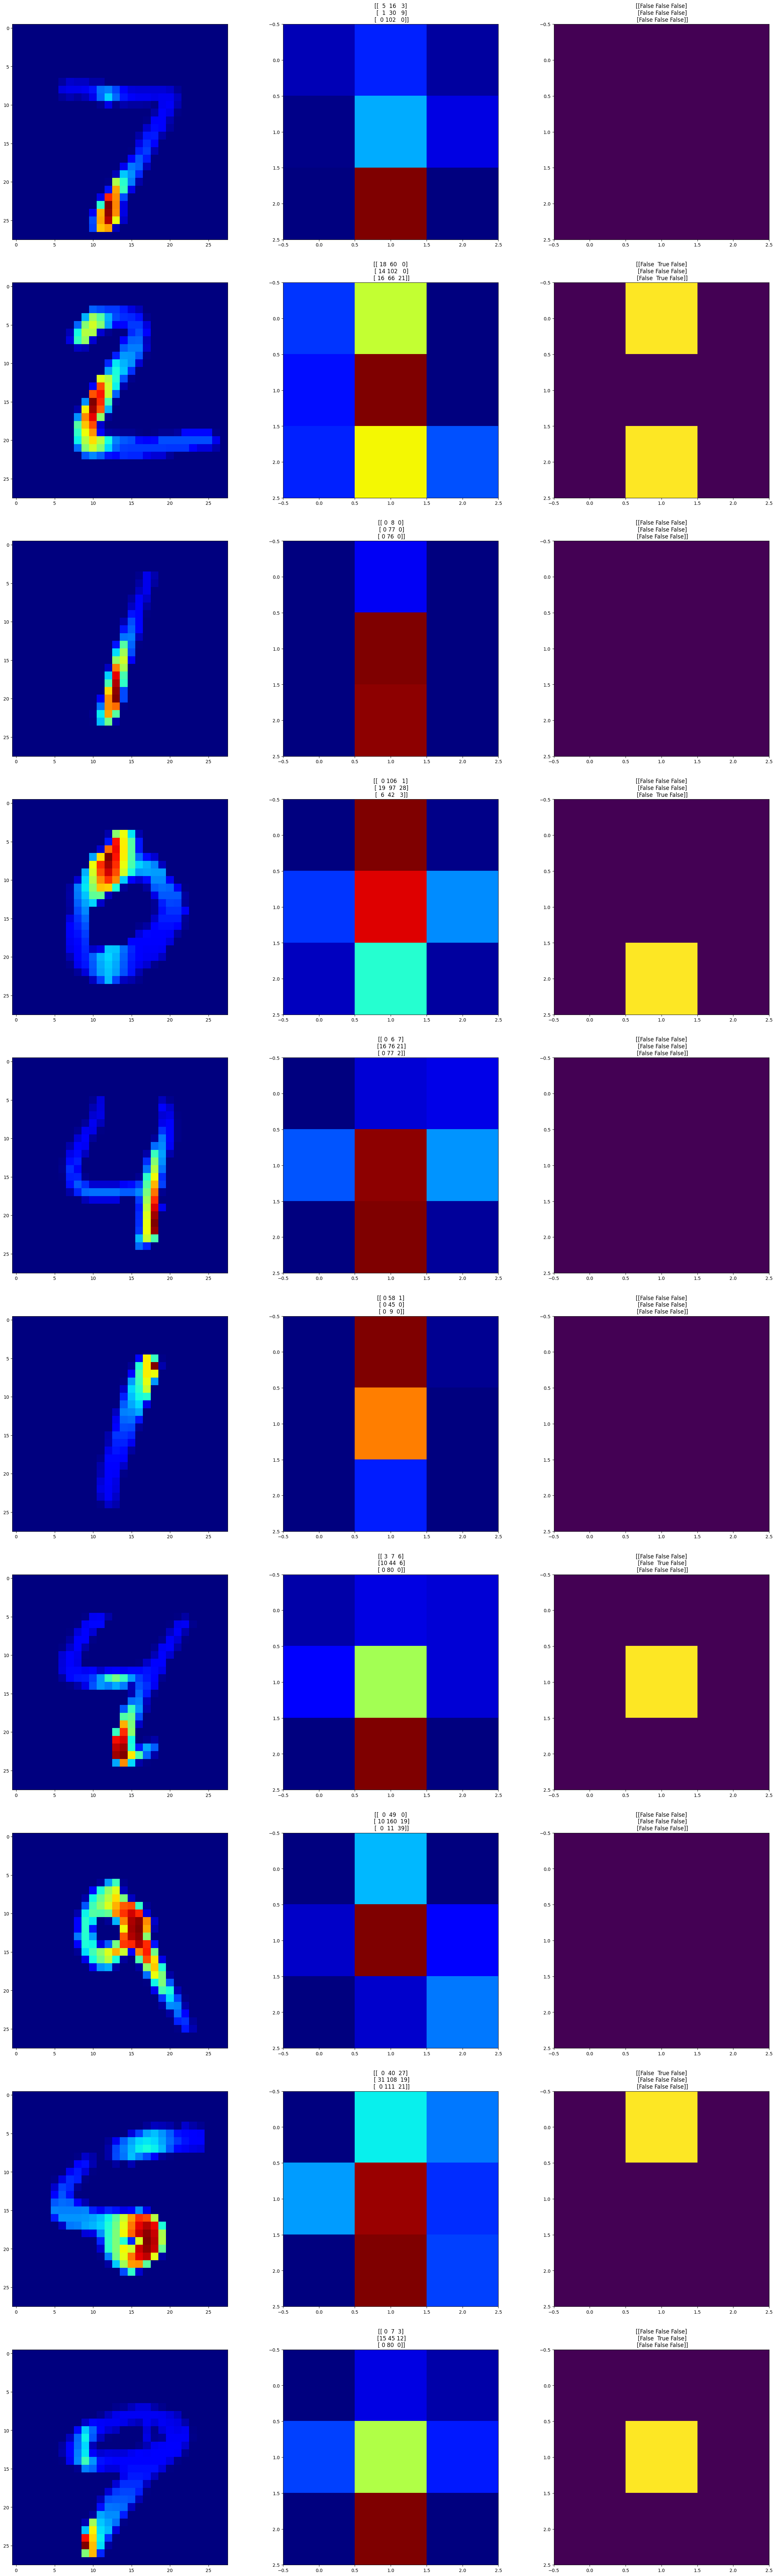

In [106]:
plt.figure(figsize = (30, 100))
for i in range(10) :
    plt.subplot(10, 3, 3*i +1)
    plt.imshow(curr_X[i], cmap = 'jet')
    
    plt.subplot(10, 3, 3*i +2)
    plt.imshow(indic[i], cmap = 'jet')
    plt.title(indic[i])
    
    plt.subplot(10, 3, 3*i +3)
    plt.imshow(problem[i])
    plt.title(problem[i].reshape((3, 3)))

In [108]:
new_mask_X = curr_X.copy()

for i in range(len(rang) -1) :
    for j in range(len(rang) -1) :
        new_mask_X[:, rang[i]:rang[i +1], rang[j]:rang[j +1]] = new_mask_X[:, rang[i]:rang[i +1], rang[j]:rang[j +1]] *problem[:, i:(i+1), j:(j+1)]

new_mask_X[new_mask_X > 0] = 1
new_mask_X = np.array(new_mask_X, dtype = bool)

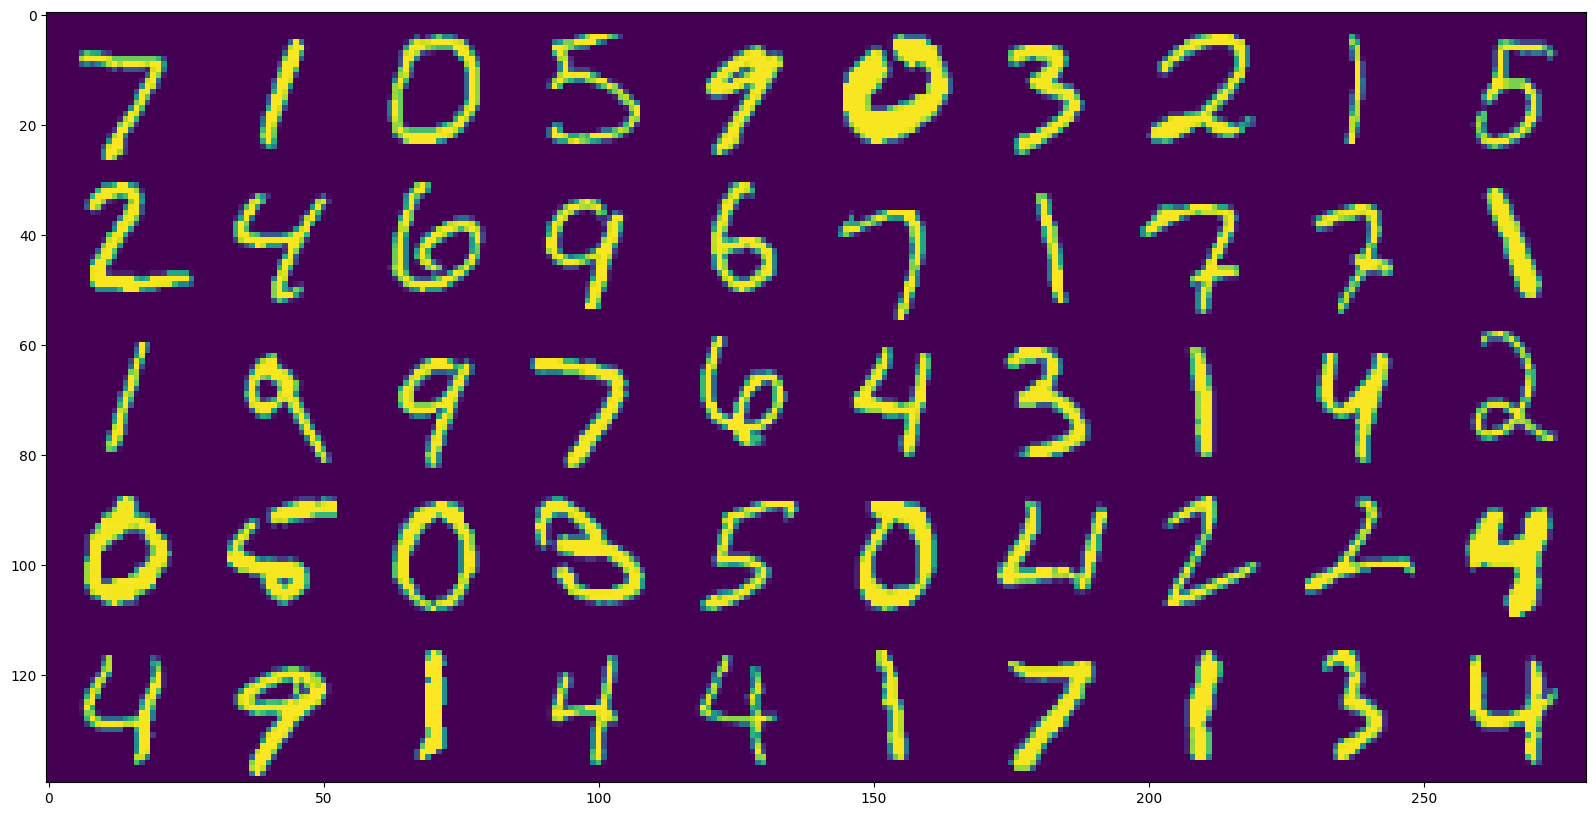

In [137]:
index = 50
images = np.array(All_X_val[:index], dtype = np.float32) /256
# images = exp_softmax(images)


new_images = images.reshape((10, 5,) + X_train.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images)

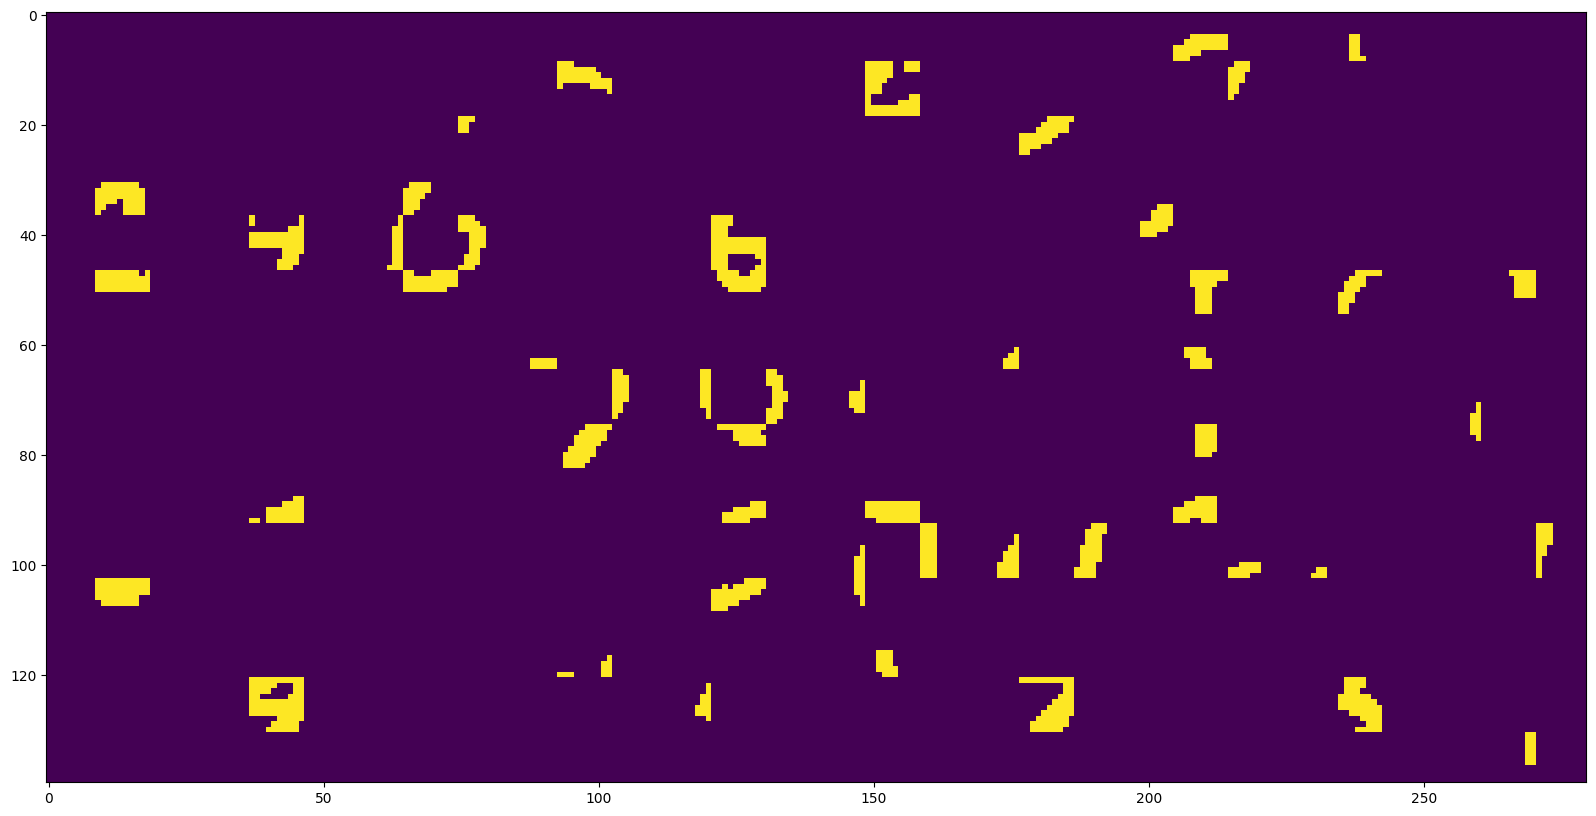

In [138]:
index = 50
images = np.array(new_mask_X_val[:index], dtype = np.float32) /256
# images = exp_softmax(images)


new_images = images.reshape((10, 5,) + X_train.shape[-2:])
new_images = np.concatenate(new_images, axis = 2)
new_images = np.concatenate(new_images, axis = 0)

fig = plt.figure(figsize = (20, 10))
plt.imshow(new_images)

In [101]:
new_mask_X_train = new_mask_X.copy()
new_mask_Y_train = problem.reshape((new_mask_X.shape[0], 9))

In [110]:
new_mask_X_val = new_mask_X.copy()
new_mask_Y_val = problem.reshape((new_mask_X.shape[0], 9))

In [112]:
# np.savez('../../../DATAS/mnist_masked.npz', x_train = new_mask_X_train, y_train = new_mask_Y_train, x_test = new_mask_X_val, y_test = new_mask_Y_val, allow_pickle = False) # Thèses\Benchmark\CVAE 2D

[False False False False False False False  True False]


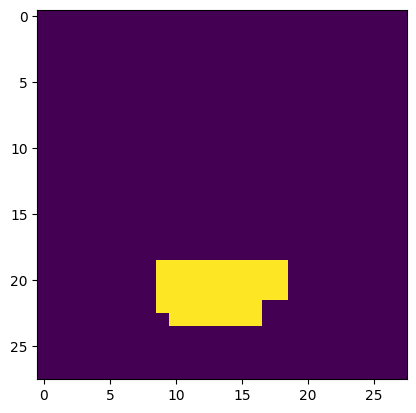

In [121]:
i = 3

print(new_mask_Y_val[i])
plt.imshow(new_mask_X_val[i])

In [123]:
new_mask_Y_val.sum(axis = 0), new_mask_Y_val.sum()

(array([ 213, 3234,  699, 1035, 1537, 1597,  503, 3546,  479]), 12843)

In [124]:
new_mask_Y_train.sum(axis = 0), new_mask_Y_train.sum()

(array([ 1193, 18702,  4321,  6060,  9481,  9832,  3258, 20793,  2951]), 76591)

In [162]:
new_mask_Y_train.sum(axis = 1), new_mask_Y_train.sum(axis = 1).mean(), new_mask_Y_train.sum(axis = 1).max(),new_mask_Y_train.sum(axis = 1).min()

(array([1, 4, 1, ..., 1, 3, 1]), 1.2765166666666667, 6, 0)

In [179]:
new_mask_Y_train.shape

(60000, 9)

In [165]:
test = pd.DataFrame(new_mask_Y_train, columns = range(9))
test["label"] = All_Y_train
# test.groupby("label").sum()
test.groupby("label").mean().sum(axis = 1)

label
0    2.178119
1    0.639721
2    1.527022
3    1.464851
4    1.049469
5    1.335547
6    1.243325
7    1.106305
8    1.262519
9    1.050765
dtype: float64

In [187]:
test = pd.DataFrame(new_mask_Y_train.sum(axis = 1), columns = ["mean"])
test["label"] = All_Y_train
test_2 = test.groupby("label").mean()
test_2["std"] = test.groupby("label").std()
test_2["min"] = test.groupby("label").min()
test_2["max"] = test.groupby("label").max()
test_2

,mean,std,min,max
label,,,,
0,2.178119,1.269567,0,6
1,0.639721,0.721785,0,4
2,1.527022,1.053317,0,6
3,1.464851,1.008219,0,6
4,1.049469,0.950288,0,5
5,1.335547,1.015438,0,6
6,1.243325,0.972637,0,6
7,1.106305,0.923062,0,5
8,1.262519,1.033852,0,5


In [188]:
test = pd.DataFrame(new_mask_Y_val.sum(axis = 1), columns = ["mean"])
test["label"] = All_Y_val
test_2 = test.groupby("label").mean()
test_2["std"] = test.groupby("label").std()
test_2["min"] = test.groupby("label").min()
test_2["max"] = test.groupby("label").max()
test_2

,mean,std,min,max
label,,,,
0,2.177551,1.211583,0,6
1,0.687225,0.750053,0,3
2,1.544574,1.077928,0,5
3,1.442574,0.956522,0,5
4,1.060081,0.939264,0,4
5,1.345291,0.966121,0,5
6,1.302714,1.015148,0,5
7,1.148833,0.923684,0,5
8,1.196099,1.042541,0,5


,nb,std,min,max
label,,,,
0,2.177551,1.211583,0,6
1,0.687225,0.750053,0,3
2,1.544574,1.077928,0,5
3,1.442574,0.956522,0,5
4,1.060081,0.939264,0,4
5,1.345291,0.966121,0,5
6,1.302714,1.015148,0,5
7,1.148833,0.923684,0,5
8,1.196099,1.042541,0,5


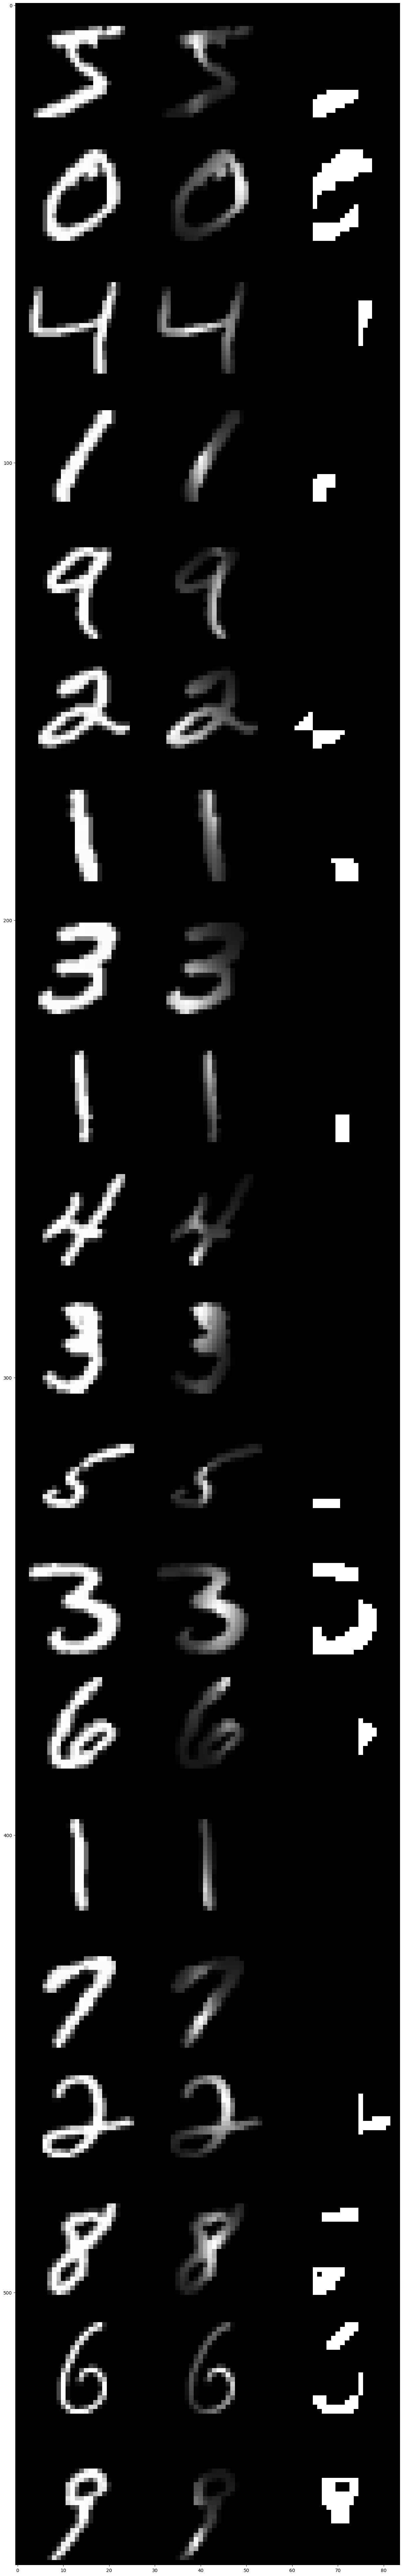

In [198]:
index = 20
img = X_train[:index]
img_dose = new_X_train[:index]
img_mask = new_mask_X_train[:index]*255


# images = exp_softmax(images)
# img = np.concatenate(img, axis = 0)
# img_dose = np.concatenate(img_dose, axis = 0)
# img_mask = np.concatenate(img_mask, axis = 0)

img = np.concatenate(np.array([img, img_dose, img_mask]), axis = 2)
img = np.concatenate(img, axis = 0)

fig = plt.figure(figsize = (15, 100))

plt.imshow(img, cmap = 'gray')



In [192]:

plt.subplot(1, 3, 1)
plt.imshow(img, cmap = 'gray')

plt.subplot(1, 3, 2)
plt.imshow(img_dose, cmap = 'jet')

plt.subplot(1, 3, 3)
plt.imshow(img_mask)